# Proyecto EVA: exploración y ruta de desarrollo

**Curso:** Despliegue de soluciones analíticas — MIAD 2026  
**Equipo:** María Valentina Páez Romero, Samuel Esteban Vargas, Felipe Delgadillo Barrera y Juan Esteban Misas Ramírez  
**Entrega:** exploración de la base agrícola EVA 2019–2025 y del índice climático RONI

Este cuaderno documenta el entendimiento del problema, la preparación de los datos, la exploración de los tres cultivos frente a la pregunta de negocio, la caracterización climática de cada periodo, las limitaciones actuales y los próximos pasos para construir el modelo, la API, el tablero y el despliegue.

## 1. Problema y contexto

Colombia enfrenta un nuevo episodio de El Niño. El IDEAM lo declaró oficialmente con una intensidad entre fuerte y muy fuerte, con un 83% de probabilidad de que se mantenga al menos hasta marzo de 2027 (Portafolio, 2026), y el Gobierno declaró la situación de desastre nacional mediante el Decreto 0802 del 23 de julio de 2026 (El Colombiano, 2026). El agro es uno de los sectores más expuestos, porque buena parte de la producción de alimentos básicos depende de la lluvia.

El proyecto se enfoca en arroz, papa y caña por su peso en la dieta y porque responden de forma distinta al clima: el arroz combina riego y secano, la papa es de ciclo corto y la caña es un cultivo permanente. El riesgo tampoco se distribuye por igual entre regiones y sistemas productivos (Contexto Ganadero, 2026). Sin embargo, la información agrícola disponible describe lo que ya ocurrió y no permite anticipar qué rendimiento esperar en un municipio bajo un escenario climático.

### Pregunta de negocio
¿Cuál es el rendimiento esperado en toneladas por hectárea (t/ha) de arroz, papa y caña en un municipio y periodo dados, y cuánto difiere esa estimación bajo un escenario de El Niño frente a uno neutro o de La Niña?

### Preguntas de apoyo
- ¿Cómo ha evolucionado el rendimiento de arroz, papa y caña, y de sus variantes, entre 2019 y 2025?
- ¿Qué diferencia se observa en el rendimiento de cada cultivo durante El Niño 2023–2024 frente al resto del periodo?
- ¿Responden distinto al clima las variantes de un mismo cultivo (arroz riego frente a secano, papa criolla frente a las demás, caña de azúcar frente a panelera)?
- ¿En qué regiones o municipios el rendimiento parece más sensible al escenario climático?

**Usuarios:** las secretarías de agricultura departamentales son los usuarios principales; los gremios y las aseguradoras agrícolas, usuarios secundarios.

## 2. Fuentes y flujo de datos

El proyecto usa dos fuentes:

- **Evaluaciones Agropecuarias Municipales (EVA) 2019–2025, Base Agrícola**, publicada por la UPRA en datos.gov.co mediante la API Socrata (`uejq-wxrr`). Contiene la variable a estimar: el rendimiento.
- **Índice Oceánico Relativo de El Niño (RONI)**, publicado por el Centro de Predicción Climática (CPC) de la NOAA, indicador oficial de ENSO desde febrero de 2026. Define el escenario climático de cada periodo.

El flujo reproducible del repositorio es:

```text
EVA:  API datos.gov.co -> JSON crudo (DVC) -> limpiar_eva.py  -> eva_modelo.csv    -> EDA
RONI: archivo NOAA/CPC -> TXT crudo (DVC)  -> limpiar_roni.py -> roni_periodos.csv -> EDA
```

Los scripts están en `src/`: `descargar_eva.py`, `limpiar_eva.py` y `eda_eva.py` para EVA; `descargar_roni.py`, `limpiar_roni.py` y `eda_roni.py` para el RONI. Los crudos no se versionan en Git; sus archivos `.dvc` permiten recuperarlos desde el almacenamiento del equipo. El cruce entre ambas fuentes se construirá en la Entrega 2; en este cuaderno el RONI solo se usa para identificar los periodos de cada fase en las gráficas.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")

RAIZ = Path.cwd()
if not (RAIZ / "data").exists() and (RAIZ.parent / "data").exists():
    RAIZ = RAIZ.parent

RUTA_CRUDO = RAIZ / "data" / "raw" / "eva_2019_2025.json"
RUTA_MODELO = RAIZ / "data" / "processed" / "eva_modelo.csv"
RUTA_EDA = RAIZ / "data" / "processed" / "eda"
RUTA_RONI = RAIZ / "data" / "processed" / "roni_periodos.csv"

print(f"Directorio del proyecto: {RAIZ}")
print(f"Existe el dato crudo: {RUTA_CRUDO.exists()}")
print(f"Existe el dato procesado: {RUTA_MODELO.exists()}")
print(f"Existe el RONI por periodo: {RUTA_RONI.exists()}")

Directorio del proyecto: c:\Users\EstebanMR\Proyectos_MIAD\Proyecto_DSA\Proyecto-despliegue-soluciones-analytics
Existe el dato crudo: True
Existe el dato procesado: True
Existe el RONI por periodo: True


## 3. Carga y revisión inicial

Se cargan dos capas con propósitos distintos:

- **Capa cruda:** evidencia de la fuente y control de cobertura original.
- **Capa procesada:** tabla analítica con cultivos, periodos y variantes definidos por el equipo.

La capa procesada es la que se utilizará para las tablas y gráficas de esta exploración.

In [3]:
if not RUTA_MODELO.exists():
    raise FileNotFoundError(
        "No existe data/processed/eva_modelo.csv. "
        "Ejecute primero: python src/limpiar_eva.py"
    )

datos = pd.read_csv(RUTA_MODELO, dtype={"periodo": str})
datos["a_o"] = pd.to_numeric(datos["a_o"], errors="coerce").astype("Int64")
for columna in ["rea_sembrada", "rea_cosechada", "producci_n", "rendimiento"]:
    datos[columna] = pd.to_numeric(datos[columna], errors="coerce")

print(f"Filas procesadas: {len(datos):,}")
print(f"Columnas procesadas: {datos.shape[1]}")
display(datos.head())

Filas procesadas: 14,526
Columnas procesadas: 13


,c_digo_dane_departamento,departamento,c_digo_dane_municipio,municipio,cultivo,periodo,a_o,ciclo_del_cultivo,variante,rea_sembrada,rea_cosechada,producci_n,rendimiento
0,50.00,Meta,50006,Acacías,Arroz,2019A,2019,Transitorio,Arroz secano mecanizado,452.00,445.00,"2,373.10",5.33
1,50.00,Meta,50006,Acacías,Arroz,2019B,2019,Transitorio,Arroz secano mecanizado,16.20,16.20,91.20,5.63
2,50.00,Meta,50006,Acacías,Arroz,2020A,2020,Transitorio,Arroz secano mecanizado,384.00,384.00,"1,920.00",5.00
3,50.00,Meta,50006,Acacías,Arroz,2020B,2020,Transitorio,Arroz secano mecanizado,15.00,15.00,84.00,5.60
4,50.00,Meta,50006,Acacías,Arroz,2021A,2021,Transitorio,Arroz secano mecanizado,678.00,611.00,"3,055.00",5.00


In [4]:
resumen_estructura = pd.DataFrame({
    "columna": datos.columns,
    "tipo": datos.dtypes.astype(str).values,
    "faltantes": datos.isna().sum().values,
    "porcentaje_faltante": (datos.isna().mean() * 100).round(2).values,
})
display(resumen_estructura)

print("Cultivos:", sorted(datos["cultivo"].dropna().unique()))
print("Variantes:", sorted(datos["variante"].dropna().unique()))
print("Municipios:", datos["c_digo_dane_municipio"].nunique())
print("Periodos:", datos["periodo"].min(), "a", datos["periodo"].max())

,columna,tipo,faltantes,porcentaje_faltante
0,c_digo_dane_departamento,float64,0,0.00
1,departamento,object,0,0.00
2,c_digo_dane_municipio,int64,0,0.00
3,municipio,object,0,0.00
4,cultivo,object,0,0.00
5,periodo,object,0,0.00
6,a_o,Int64,0,0.00
7,ciclo_del_cultivo,object,0,0.00
8,variante,object,0,0.00
9,rea_sembrada,float64,0,0.00


Cultivos: ['Arroz', 'Caña', 'Papa']
Variantes: ['Arroz riego', 'Arroz secano manual', 'Arroz secano mecanizado', 'Caña de azúcar', 'Caña panelera', 'Papa criolla', 'Papa todas las variedades', 'Papa todas menos criolla']
Municipios: 938
Periodos: 2019 a 2025B


## 4. Reglas de preparación aplicadas

Las reglas se ejecutan en `src/limpiar_eva.py` y se verifican aquí:

1. Se conservan arroz, papa y caña.
2. Arroz y papa usan periodos semestrales (`A` y `B`); caña usa periodos anuales.
3. Se excluye caña miel.
4. Se conservan las variantes del arroz y las dos variantes de caña definidas por el equipo.
5. La papa criolla no se suma a papa total; se deriva papa todas menos criolla.
6. El rendimiento se recalcula como producción dividida por área cosechada.

Estas reglas evitan doble conteo y mantienen la granularidad municipio-periodo-variante.

In [5]:
conteo_cultivo = datos.groupby(["cultivo", "variante"], as_index=False).agg(
    filas=("cultivo", "size"),
    municipios=("c_digo_dane_municipio", "nunique"),
    periodos=("periodo", "nunique"),
)
display(conteo_cultivo)

periodos_no_validos = datos[
    ((datos["cultivo"].isin(["Arroz", "Papa"])) &
     ~datos["periodo"].astype(str).str.match(r"^\d{4}[AB]$"))
    | ((datos["cultivo"] == "Caña") &
       ~datos["periodo"].astype(str).str.match(r"^\d{4}$"))
]

print(f"Filas con periodo incompatible con el cultivo: {len(periodos_no_validos)}")
print(f"Filas de caña miel: {(datos['variante'] == 'Caña miel').sum()}")
print(f"Filas con área cosechada igual a cero: {(datos['rea_cosechada'] == 0).sum():,}")

,cultivo,variante,filas,municipios,periodos
0,Arroz,Arroz riego,1635,137,14
1,Arroz,Arroz secano manual,2019,185,14
2,Arroz,Arroz secano mecanizado,1184,109,14
3,Caña,Caña de azúcar,359,57,7
4,Caña,Caña panelera,3951,581,7
5,Papa,Papa criolla,1509,145,14
6,Papa,Papa todas las variedades,196,49,14
7,Papa,Papa todas menos criolla,3673,305,14


Filas con periodo incompatible con el cultivo: 0
Filas de caña miel: 0
Filas con área cosechada igual a cero: 642


In [6]:
rendimiento_recalculado = pd.Series(
    np.where(
        datos["rea_cosechada"] > 0,
        datos["producci_n"] / datos["rea_cosechada"],
        np.nan,
    ),
    index=datos.index,
)
diferencia = (datos["rendimiento"] - rendimiento_recalculado).abs()
diferencia_relativa = diferencia / rendimiento_recalculado.abs().replace(0, np.nan)

control_rendimiento = pd.Series({
    "filas_con_rendimiento_recalculable": np.isfinite(rendimiento_recalculado).sum(),
    "filas_con_diferencia_mayor_al_5_por_ciento": (diferencia_relativa > 0.05).sum(),
    "diferencia_relativa_mediana": diferencia_relativa.median(),
})
display(control_rendimiento.to_frame("valor"))

print("La métrica analítica de rendimiento usa producción / área cosechada.")

,valor
filas_con_rendimiento_recalculable,"13,884.00"
filas_con_diferencia_mayor_al_5_por_ciento,0.00
diferencia_relativa_mediana,0.00


La métrica analítica de rendimiento usa producción / área cosechada.


## 5. Exploración descriptiva

Primero se resumen cobertura, producción, área cosechada y rendimiento. La mediana representa el comportamiento del municipio típico; el rendimiento agregado se calcula como producción total dividida por área cosechada total y sirve para describir el conjunto productivo.

In [7]:
resumen = datos.groupby(["cultivo", "variante"], as_index=False).agg(
    filas=("cultivo", "size"),
    municipios=("c_digo_dane_municipio", "nunique"),
    produccion_total=("producci_n", "sum"),
    area_cosechada_total=("rea_cosechada", "sum"),
    rendimiento_mediano=("rendimiento", "median"),
)
resumen["rendimiento_agregado"] = (
    resumen["produccion_total"] / resumen["area_cosechada_total"].replace(0, np.nan)
)
display(resumen.sort_values(["cultivo", "variante"]))

,cultivo,variante,filas,municipios,produccion_total,area_cosechada_total,rendimiento_mediano,rendimiento_agregado
0,Arroz,Arroz riego,1635,137,"11,834,367.06","1,776,470.49",6.26,6.66
1,Arroz,Arroz secano manual,2019,185,"1,347,992.44","496,230.35",2.38,2.72
2,Arroz,Arroz secano mecanizado,1184,109,"12,691,252.46","2,355,714.49",5.13,5.39
3,Caña,Caña de azúcar,359,57,"217,581,510.34","1,900,588.87",113.31,114.48
4,Caña,Caña panelera,3951,581,"92,000,570.86","1,501,600.65",50.00,61.27
5,Papa,Papa criolla,1509,145,"1,440,236.51","90,417.52",14.00,15.93
6,Papa,Papa todas las variedades,196,49,"297,004.06","14,367.96",18.00,20.67
7,Papa,Papa todas menos criolla,3673,305,"24,355,748.01","1,064,068.93",20.00,22.89


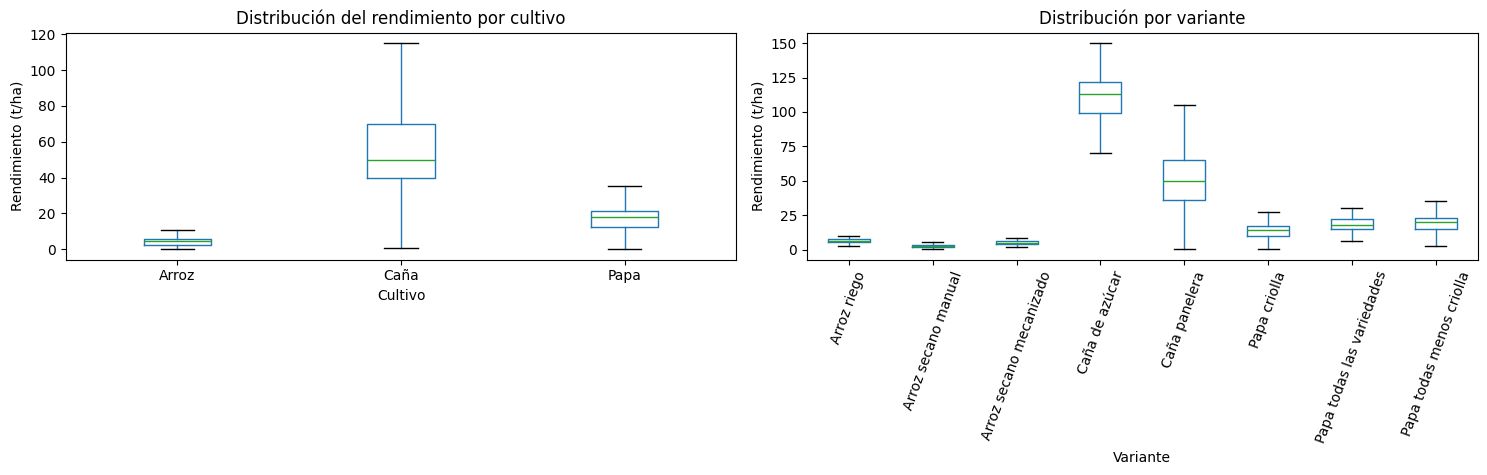

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
datos.boxplot(column="rendimiento", by="cultivo", ax=ejes[0], grid=False, showfliers=False)
ejes[0].set_title("Distribución del rendimiento por cultivo")
ejes[0].set_xlabel("Cultivo")
ejes[0].set_ylabel("Rendimiento (t/ha)")
ejes[0].get_figure().suptitle("")

datos.boxplot(column="rendimiento", by="variante", ax=ejes[1], grid=False, showfliers=False)
ejes[1].set_title("Distribución por variante")
ejes[1].set_xlabel("Variante")
ejes[1].set_ylabel("Rendimiento (t/ha)")
ejes[1].tick_params(axis="x", rotation=70)
ejes[1].get_figure().suptitle("")
plt.tight_layout()
plt.show()


## 6. Caracterización climática de los periodos (RONI)

EVA no trae variables climáticas, así que cada periodo se caracteriza con el RONI. El índice se agrega en `src/limpiar_roni.py`:

- **Arroz y papa (semestral):** promedio del semestre (enero–junio y julio–diciembre), clasificado como El Niño (≥ 0,5 °C), La Niña (≤ −0,5 °C) o neutro.
- **Caña (anual):** un promedio anual puede diluir los episodios cuando el año combina fases, por lo que se mide la exposición del año: la proporción de trimestres en El Niño (`prop_nino`) y en La Niña (`prop_nina`).


Fase por semestre (arroz y papa):


,periodo,roni_medio,fase,prop_nino,prop_nina
2,2019A,0.51,El Niño,0.67,0.00
3,2019B,0.10,Neutro,0.00,0.00
4,2020A,-0.21,Neutro,0.00,0.33
5,2020B,-1.17,La Niña,0.00,1.00
6,2021A,-0.95,La Niña,0.00,1.00
7,2021B,-0.97,La Niña,0.00,1.00
8,2022A,-1.15,La Niña,0.00,1.00
9,2022B,-1.00,La Niña,0.00,1.00
10,2023A,-0.36,Neutro,0.00,0.50
11,2023B,1.08,El Niño,1.00,0.00


Exposición por año (caña):


,periodo,roni_medio,fase,prop_nino,prop_nina
19,2019,0.30,Neutro,0.33,0.00
20,2020,-0.69,La Niña,0.00,0.67
21,2021,-0.96,La Niña,0.00,1.00
22,2022,-1.07,La Niña,0.00,1.00
23,2023,0.36,Neutro,0.50,0.25
24,2024,-0.23,Neutro,0.17,0.42
25,2025,-0.72,La Niña,0.00,0.75


Semestres 2019A-2025B por fase: {'La Niña': 8, 'Neutro': 4, 'El Niño': 2}
Semestres de El Niño: ['2019A', '2023B']


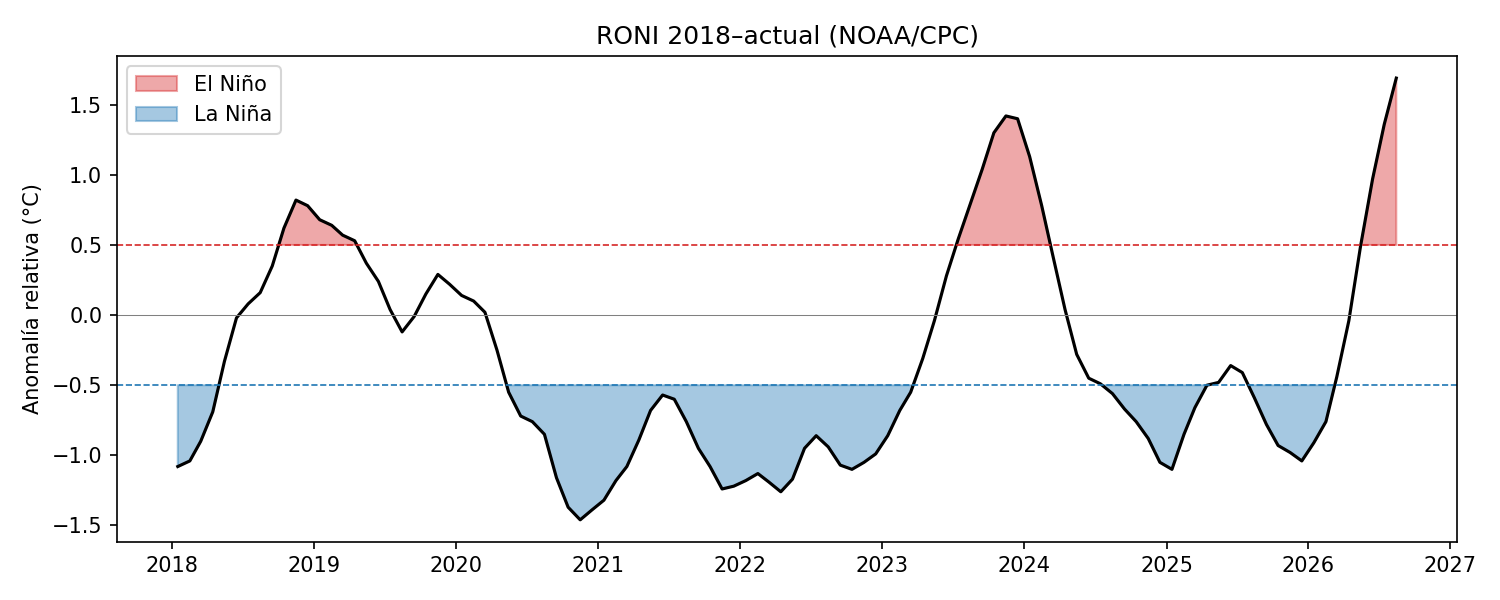

In [9]:
from IPython.display import Image

if not RUTA_RONI.exists():
    raise FileNotFoundError(
        "No existe data/processed/roni_periodos.csv. "
        "Ejecute primero: python src/descargar_roni.py y python src/limpiar_roni.py"
    )

roni = pd.read_csv(RUTA_RONI, dtype={"periodo": str})
roni_sem = roni[(roni["frecuencia"] == "semestral") & roni["periodo"].between("2019A", "2025B")]
roni_anual = roni[(roni["frecuencia"] == "anual") & roni["periodo"].between("2019", "2025")]

columnas_roni = ["periodo", "roni_medio", "fase", "prop_nino", "prop_nina"]
print("Fase por semestre (arroz y papa):")
display(roni_sem[columnas_roni])
print("Exposición por año (caña):")
display(roni_anual[columnas_roni])

conteo_fases = roni_sem["fase"].value_counts()
print(f"Semestres 2019A-2025B por fase: {conteo_fases.to_dict()}")
print("Semestres de El Niño:", roni_sem.loc[roni_sem["fase"] == "El Niño", "periodo"].tolist())

grafica_roni = RUTA_EDA / "roni_serie.png"
if grafica_roni.exists():
    display(Image(filename=str(grafica_roni)))
else:
    print("Ejecute python src/eda_roni.py para generar la gráfica de la serie.")

In [12]:
from matplotlib.patches import Patch

COLORES_FASE = {"El Niño": "tab:red", "La Niña": "tab:blue"}
INTENSIDAD_SEMESTRAL = {
    fase: roni_sem.set_index("periodo")["fase"].eq(fase).astype(float)
    for fase in COLORES_FASE
}
INTENSIDAD_ANUAL = {
    "El Niño": roni_anual.set_index("periodo")["prop_nino"],
    "La Niña": roni_anual.set_index("periodo")["prop_nina"],
}


def resumen_periodo(tabla: pd.DataFrame) -> pd.DataFrame:
    """Mediana municipal, rendimiento agregado y cobertura por periodo y variante."""
    salida = tabla.groupby(["periodo", "variante"], as_index=False).agg(
        rendimiento_mediano=("rendimiento", "median"),
        produccion_total=("producci_n", "sum"),
        area_cosechada_total=("rea_cosechada", "sum"),
        municipios=("c_digo_dane_municipio", "nunique"),
    )
    salida["rendimiento_agregado"] = (
        salida["produccion_total"] / salida["area_cosechada_total"].replace(0, np.nan)
    )
    return salida


def sombrear_fases(eje, periodos: list, intensidad: dict) -> None:
    """Sombrea cada periodo según su fase; la opacidad refleja la exposición."""
    for i, periodo in enumerate(periodos):
        for fase, serie in intensidad.items():
            valor = serie.get(periodo, 0)
            if pd.notna(valor) and valor > 0:
                eje.axvspan(i - 0.5, i + 0.5, color=COLORES_FASE[fase],
                            alpha=0.25 * valor, linewidth=0)


def graficar_cultivo(tabla_periodo: pd.DataFrame, cultivo: str, intensidad: dict) -> None:
    """Dos paneles (mediana municipal y rendimiento agregado) con las fases sombreadas."""
    periodos = sorted(tabla_periodo["periodo"].unique())
    posicion = {p: i for i, p in enumerate(periodos)}
    fig, ejes = plt.subplots(1, 2, figsize=(16, 5))
    metricas = [("rendimiento_mediano", "mediana municipal"),
                ("rendimiento_agregado", "rendimiento agregado")]
    for eje, (columna, nombre) in zip(ejes, metricas):
        sombrear_fases(eje, periodos, intensidad)
        for variante, grupo in tabla_periodo.groupby("variante"):
            grupo = grupo.sort_values("periodo")
            eje.plot(grupo["periodo"].map(posicion), grupo[columna], marker="o", label=variante)
        eje.set_xticks(range(len(periodos)))
        eje.set_xticklabels(periodos, rotation=45)
        eje.set_title(f"{cultivo}: {nombre} por periodo")
        eje.set_xlabel("Periodo")
        eje.set_ylabel("Rendimiento (t/ha)")
        lineas, etiquetas = eje.get_legend_handles_labels()
        lineas += [Patch(color=c, alpha=0.25) for c in COLORES_FASE.values()]
        etiquetas += list(COLORES_FASE)
        eje.legend(lineas, etiquetas, fontsize=8)
    plt.tight_layout()
    plt.show()

## 7. Arroz: riego frente a secano

Se compara el rendimiento por variante y periodo. Las franjas de color marcan los semestres de El Niño (rojo) y La Niña (azul) según el RONI; los demás son neutros. Esto permite ubicar visualmente el episodio 2023–2024, pero no es una estimación del efecto climático: en esos mismos periodos también pudieron cambiar precios, insumos y área sembrada.

Se muestran dos agregaciones: la mediana municipal (el municipio típico) y el rendimiento agregado (producción total sobre área cosechada total). No se deben interpretar como la misma métrica.

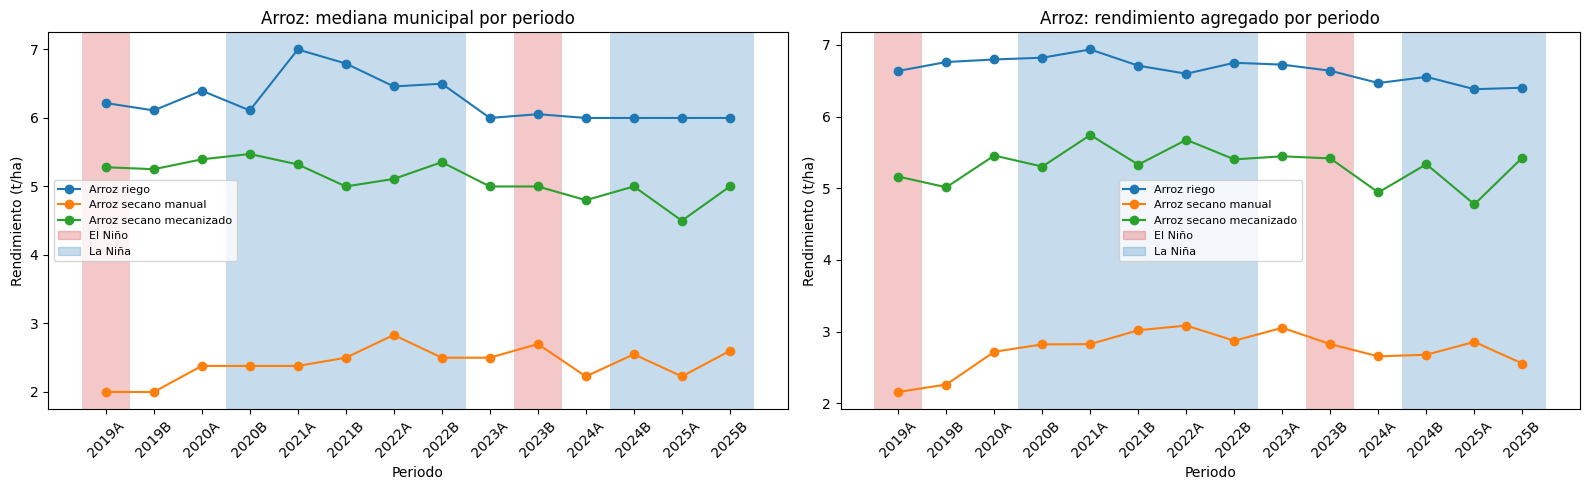

,periodo,variante,rendimiento_mediano,produccion_total,area_cosechada_total,municipios,rendimiento_agregado
0,2019A,Arroz riego,6.22,"830,834.49","125,193.76",122,6.64
1,2019A,Arroz secano manual,2.00,"96,033.83","44,521.45",143,2.16
2,2019A,Arroz secano mecanizado,5.28,"1,200,821.66","232,602.79",85,5.16
3,2019B,Arroz riego,6.11,"956,742.71","141,513.99",123,6.76
4,2019B,Arroz secano manual,2.00,"66,584.27","29,452.70",123,2.26
5,2019B,Arroz secano mecanizado,5.25,"299,951.46","59,836.59",81,5.01
6,2020A,Arroz riego,6.40,"904,963.72","133,157.36",118,6.80
7,2020A,Arroz secano manual,2.38,"126,509.23","46,553.45",149,2.72
8,2020A,Arroz secano mecanizado,5.40,"1,467,216.34","268,915.96",84,5.46
9,2020B,Arroz riego,6.11,"1,020,698.78","149,637.45",119,6.82


In [13]:
arroz = datos[datos["cultivo"] == "Arroz"].copy()
arroz_periodo = resumen_periodo(arroz)
graficar_cultivo(arroz_periodo, "Arroz", INTENSIDAD_SEMESTRAL)
display(arroz_periodo)


In [ ]:
linea_base = arroz.groupby("variante", as_index=False).agg(
    rendimiento_mediano_base=("rendimiento", "median"),
    municipios=("c_digo_dane_municipio", "nunique"),
)
riego = linea_base.loc[
    linea_base["variante"] == "Arroz riego", "rendimiento_mediano_base"
].iloc[0]
secano = linea_base.loc[
    linea_base["variante"].str.contains("secano"), "rendimiento_mediano_base"
].mean()
brecha = (riego - secano) / riego * 100

print(f"Mediana base de arroz riego: {riego:.2f} t/ha")
print(f"Mediana promedio de arroz secano: {secano:.2f} t/ha")
print(f"Brecha descriptiva frente a riego: {brecha:.1f}%")
display(linea_base)

print(
    "Esta brecha es descriptiva y no demuestra un efecto de El Niño. "
    "Contrastar la pregunta de apoyo requiere cruzar EVA con el RONI por periodo que se hará en entregas futuras"
)

Mediana base de arroz riego: 6.26 t/ha
Mediana promedio de arroz secano: 3.76 t/ha
Brecha descriptiva frente a riego: 40.0%


,variante,rendimiento_mediano_base,municipios
0,Arroz riego,6.26,137
1,Arroz secano manual,2.38,185
2,Arroz secano mecanizado,5.13,109


Esta brecha es descriptiva y no demuestra un efecto de El Niño. Contrastar la pregunta de apoyo requiere cruzar EVA con el RONI por periodo (Entrega 2).


## 8. Papa: criolla frente a las demás variedades

La papa se analiza con dos variantes: la criolla y la derivada "todas menos criolla" (total menos criolla). En las llaves municipio-periodo donde la criolla supera al total, la limpieza conserva solo el total ("Papa todas las variedades"); esas filas se revisan en la sección de calidad y no se mezclan aquí con las variantes derivadas.

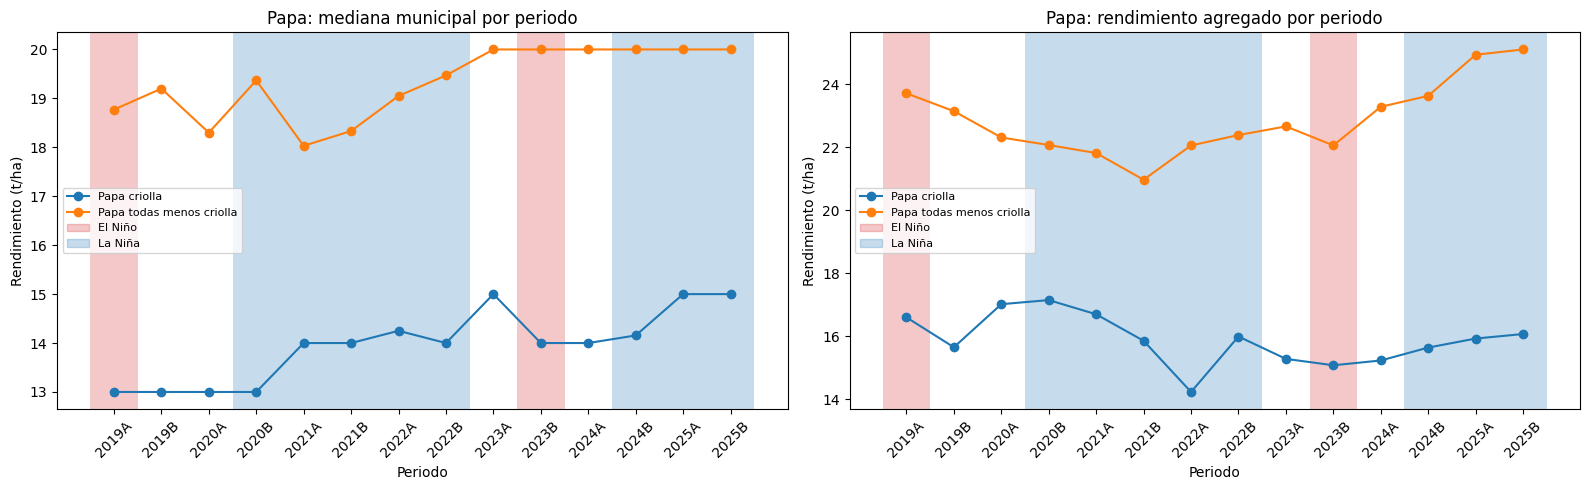

Municipios con reporte por periodo:


variante,Papa criolla,Papa todas menos criolla
periodo,,
2019A,106,269
2019B,95,236
2020A,107,270
2020B,103,247
2021A,108,271
2021B,103,247
2022A,103,261
2022B,107,263
2023A,107,265


In [15]:
papa = datos[(datos["cultivo"] == "Papa") & (datos["variante"] != "Papa todas las variedades")].copy()
papa_periodo = resumen_periodo(papa)
graficar_cultivo(papa_periodo, "Papa", INTENSIDAD_SEMESTRAL)

print("Municipios con reporte por periodo:")
display(papa_periodo.pivot(index="periodo", columns="variante", values="municipios"))

## 9. Caña: azúcar frente a panelera

La caña se reporta por año. Por eso las franjas no indican una fase única, sino la exposición del año: la opacidad es proporcional a la fracción de trimestres en El Niño (rojo) o La Niña (azul). Un año puede tener ambas.

La caña de azúcar se concentra en pocos municipios, mientras la panelera está mucho más dispersa; las medianas municipales de ambas variantes no son comparables en cobertura.

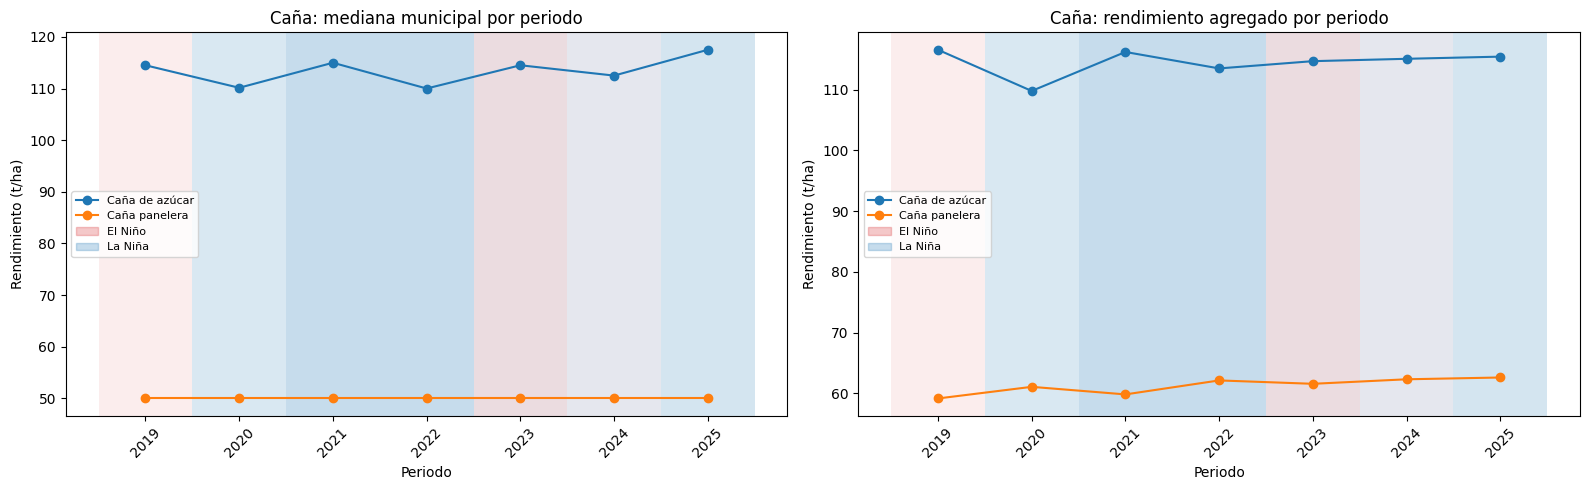

Municipios con reporte por año:


variante,Caña de azúcar,Caña panelera
periodo,,
2019,53,557
2020,51,564
2021,52,565
2022,52,565
2023,50,564
2024,51,570
2025,50,566


In [16]:
cana = datos[datos["cultivo"] == "Caña"].copy()
cana_periodo = resumen_periodo(cana)
graficar_cultivo(cana_periodo, "Caña", INTENSIDAD_ANUAL)

print("Municipios con reporte por año:")
display(cana_periodo.pivot(index="periodo", columns="variante", values="municipios"))

## 10. Calidad de datos por variante

Antes de modelar se revisan, por variante: ceros y faltantes, valores extremos de rendimiento, concentración en un mismo valor y las filas de papa que quedaron como total por inconsistencia con la criolla.

- **Extremos:** rendimiento por encima de Q3 + 3·RIQ dentro de su variante. La marca no implica error; indica que el valor debe revisarse.
- **Concentración:** porcentaje de filas con el valor más frecuente y con rendimiento entero. Las medianas planas de las gráficas anteriores (por ejemplo, caña panelera en 50 t/ha todos los años) sugieren que muchos municipios reportan valores redondeados o de referencia, lo que reduciría la variación real disponible para el modelo.

In [18]:
def resumen_calidad(grupo: pd.DataFrame) -> pd.Series:
    rendimiento = grupo["rendimiento"]
    validos = rendimiento.dropna()
    q1, q3 = validos.quantile([0.25, 0.75])
    limite = q3 + 3 * (q3 - q1)
    redondeado = validos.round(2)
    moda = redondeado.mode()
    valor_moda = moda.iloc[0] if len(moda) else np.nan
    parte_decimal = validos % 1
    return pd.Series({
        "filas": len(grupo),
        "area_cosechada_cero": int((grupo["rea_cosechada"] == 0).sum()),
        "rendimiento_faltante": int(rendimiento.isna().sum()),
        "p01": validos.quantile(0.01),
        "mediana": validos.median(),
        "p99": validos.quantile(0.99),
        "maximo": validos.max(),
        "extremos_altos": int((validos > limite).sum()),
        "valor_mas_frecuente": valor_moda,
        "pct_valor_mas_frecuente": (redondeado == valor_moda).mean() * 100,
        "pct_rendimiento_entero": (np.isclose(parte_decimal, 0) | np.isclose(parte_decimal, 1)).mean() * 100,
    })

calidad = pd.DataFrame({
    (cultivo, variante): resumen_calidad(grupo)
    for (cultivo, variante), grupo in datos.groupby(["cultivo", "variante"])
}).T
display(calidad)

inconsistentes = datos[datos["variante"] == "Papa todas las variedades"]
print(f"Filas de papa conservadas como total por inconsistencia: {len(inconsistentes):,}")
display(
    inconsistentes.groupby("departamento").size()
    .sort_values(ascending=False).head(10).to_frame("filas")
)

filas  area_cosechada_cero  \
Arroz Arroz riego               1,635.00                62.00   
      Arroz secano manual       2,019.00               191.00   
      Arroz secano mecanizado   1,184.00               160.00   
Caña  Caña de azúcar              359.00                 5.00   
      Caña panelera             3,951.00                33.00   
Papa  Papa criolla              1,509.00                38.00   
      Papa todas las variedades   196.00                30.00   
      Papa todas menos criolla  3,673.00               123.00   

                                 rendimiento_faltante   p01  mediana    p99  \
Arroz Arroz riego                               62.00  3.00     6.26   9.15   
      Arroz secano manual                      191.00  0.88     2.38   6.20   
      Arroz secano mecanizado                  160.00  1.80     5.13   8.30   
Caña  Caña de azúcar                             5.00 30.00   113.31 159.99   
      Caña panelera                             33.00  5.59    50.00 124.48   
Papa  Papa criolla                              38.00  3.00    14.00  27.00   
      Papa todas las variedades                 30.00  3.00    18.00  31.75   
      Papa todas menos criolla                 123.00  4.00    20.00  55.17   

                                 maximo  extremos_altos  valor_mas_frecuente  \
Arroz Arroz riego                 10.71            0.00                 6.00   
      Arroz secano manual          8.57            1.00                 3.00   
      Arroz secano mecanizado      9.00            0.00                 4.50   
Caña  Caña de azúcar             160.00            0.00               120.00   
      Caña panelera              210.00            5.00                40.00   
Papa  Papa criolla                37.50            0.00                12.00   
      Papa todas las variedades   35.00            0.00                18.00   
      Papa todas menos criolla   283.00           57.00                20.00   

                                 pct_valor_mas_frecuente  \
Arroz Arroz riego                                   9.85   
      Arroz secano manual                           9.57   
      Arroz secano mecanizado                       7.32   
Caña  Caña de azúcar                               18.08   
      Caña panelera                                13.12   
Papa  Papa criolla                                 10.20   
      Papa todas las variedades                    14.46   
      Papa todas menos criolla                      8.25   

                                 pct_rendimiento_entero  
Arroz Arroz riego                                 26.45  
      Arroz secano manual                         25.44  
      Arroz secano mecanizado                     21.00  
Caña  Caña de azúcar                              85.59  
      Caña panelera                               94.59  
Papa  Papa criolla                                88.85  
      Papa todas las variedades                   89.16  
      Papa todas menos criolla                    59.61

Filas de papa conservadas como total por inconsistencia: 196


,filas
departamento,
Cundinamarca,56
Antioquia,50
Boyacá,36
Norte de Santander,16
Nariño,12
Santander,10
Tolima,10
Cauca,5
Caldas,1


## 11. Limitaciones y decisiones pendientes

- **Clima:** el RONI es un índice del Pacífico tropical, igual para todos los municipios en un mismo periodo. No mide la lluvia local, y la respuesta a El Niño varía entre regiones.
- **Pocos episodios:** entre 2019A y 2025B solo dos semestres quedan como El Niño (2019A y 2023B), y en la caña los episodios solo cubren parte de algunos años. Las estimaciones bajo El Niño tendrán más incertidumbre que las de los otros escenarios.
- **Causalidad:** solo se observan asociaciones. Una diferencia entre periodos puede deberse también a tendencia, precios, insumos o cambios en el área sembrada.
- **Valores redondeados:** entre el 86% y el 95% de los rendimientos de caña y papa criolla son números enteros, frente a cerca del 25% en arroz. Muchos municipios reportan valores aproximados, lo que explica las medianas planas y reduce la variación real disponible para el modelo.
- **Papa derivada:** la resta total menos criolla genera rendimientos poco convincentes (hasta 283 t/ha) cuando el área residual es muy pequeña. Las 196 filas donde la criolla supera al total se concentran en los principales departamentos productores (Cundinamarca, Antioquia y Boyacá).
- **Cobertura:** las variantes no tienen el mismo número de municipios ni periodos reportados; la caña de azúcar se concentra en pocos municipios.
- **Escala:** la caña tiene rendimientos en otra escala; los cultivos se analizan por separado.
- **Etiquetas provisionales:** `src/analisis_arroz_enso.py` usa fases definidas manualmente; se reemplazarán por `roni_periodos.csv`.

## 12. Conclusión

La base procesada permite describir el rendimiento de arroz, papa y caña por variante y periodo, y el RONI caracteriza cada periodo con una fuente oficial y reproducible. Las diferencias de nivel entre variantes son estables en el tiempo: el arroz de riego rinde más que el de secano, la caña de azúcar más del doble que la panelera en la mediana municipal y la papa no criolla más que la criolla.